# Init:

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [2]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

ModuleNotFoundError: No module named 'ijson'

In [2]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers and dates.

In [3]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Using GPU for spaCy.
Processing TriviaQA:


Classifying Answers:  14%|███████▊                                               | 11077/78260 [03:25<29:56, 37.41it/s]

ConnectionTimeoutError: Connection timeout to host https://en.wikipedia.org/w/api.php?action=opensearch&search=Parthenogenesis&limit=1&namespace=0&format=json

Classifying Answers:  14%|███████▊                                               | 11077/78260 [03:38<29:56, 37.41it/s]

In [ ]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

In [ ]:
# Visualize results:


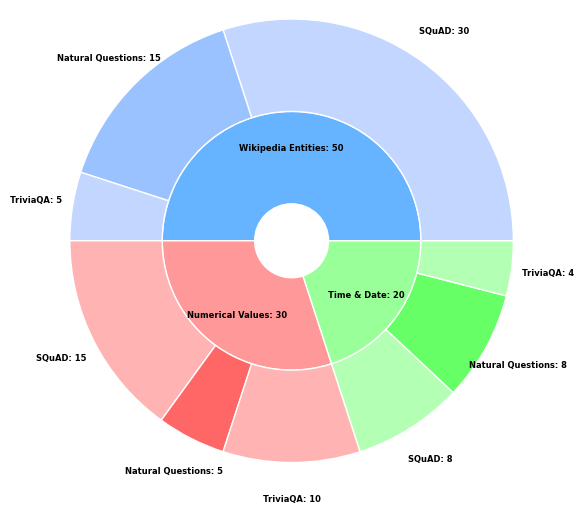

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Define data for the inner and outer rings
inner_labels = ["Wikipedia Entities", "Numerical Values", "Time & Date"]
inner_sizes = [50, 30, 20]

# Define colors
colors_inner = ["#66b3ff", "#ff9999", "#99ff99"]
colors_outer = ["#c2d6ff", "#99c2ff", "#c2d6ff", "#ffb3b3", "#ff6666", "#ffb3b3", "#b3ffb3", "#66ff66", "#b3ffb3"]

outer_labels = ["SQuAD", "Natural Questions", "TriviaQA", "SQuAD", "Natural Questions", "TriviaQA","SQuAD", "Natural Questions", "TriviaQA"]
outer_sizes = [30, 15, 5, 15, 5, 10, 8, 8, 4]

# Define colors
colors = plt.cm.Paired(np.linspace(0, 1, len(inner_labels) + len(outer_labels)))

fig, ax = plt.subplots(figsize=(6, 6))

# Plot inner ring (larger groups)
wedges_inner, _ = ax.pie(inner_sizes, radius=0.7, labels=None, colors=colors_inner, 
                          wedgeprops=dict(width=0.5, edgecolor='white'))

# Plot outer ring (smaller subcategories)
wedges_outer, _ = ax.pie(outer_sizes, radius=1.2, labels=None, colors=colors_outer, 
                          wedgeprops=dict(width=0.5, edgecolor='white'))

# Function to add labels and values inside the wedges
def add_labels(wedges, labels, sizes, radius_factor=0.85):
    for wedge, label, size in zip(wedges, labels, sizes):
        angle = (wedge.theta2 + wedge.theta1) / 2  # Find center angle
        x = radius_factor * np.cos(np.radians(angle))  # X position
        y = radius_factor * np.sin(np.radians(angle))  # Y position
        ax.text(x, y, f"{label}: {size}", ha='center', va='center', fontsize=6, color='black', fontweight="bold")

# Add labels & values inside the rings
add_labels(wedges_inner, inner_labels, inner_sizes, radius_factor=0.5)
add_labels(wedges_outer, outer_labels, outer_sizes, radius_factor=1.4)

# Ensure the chart is circular
ax.set(aspect="equal")

plt.show()


# 3. Group questions: